In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
from scipy.stats import norm

# Stile comune con accento rosso del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

alpha = 0.9         #parametro di inviluppo, controlla la larghezza del massimo centrale
i = 400             #scala del segnale
b = 50              #fondo uniforme
delta = 5.2         #controlla distanza tra le frange

#array delle posizioni:
x = np.linspace(-5, 5, 300)   

#implementazione componenti
def E(x): 
    return np.sinc(alpha*x/np.pi)**2

def C(x):
    return np.cos(delta*x)**2


#funzione principale
def mu(x):
    return b+i*E(x)*C(x)

#invuluppo superiore
def Inv(x):
    return b+i*E(x)


fig, ax = plt.subplots()

plt.plot(x,mu(x),color = AZZURRO, label ="modello completo")
plt.plot(x,Inv(x), color = ORO, linestyle = '--', label = "inviluppo superiore")
ax.set(xlabel="x(mm)", ylabel="mu")
ax.axhline(b, color=ROSSO, lw=2, label="fondo B")
plt.title("Costruzione del modello")
ax.legend()
plt.show()


#for i in x
#    



if np.all(np.isfinite(mu(x))): 
    print("tuti i valori di mu sono finiti")
else:
    print("almeno un valore di mu non è finito")

if np.all(mu(x)>=0):
    print("tutti i valori di mu sono non negativi")
else:
    print("almeno un valore di mu è negativo")


if np.allclose(mu(x), mu(x)[::-1]):
   print("mu è simmetrica")
else:
    print("mu non è simmetrica")

mu_0 = mu(0.0)
print(f"valore in x=0: {mu_0} (valore atteso B+I={b+i})") 








: 

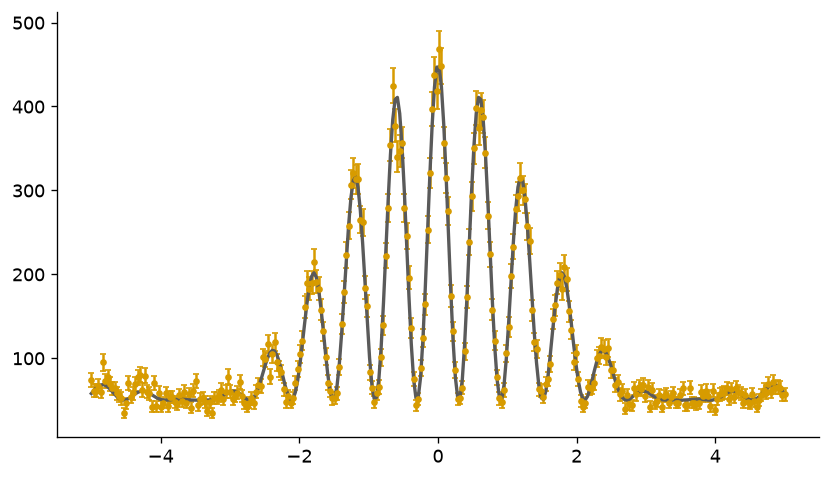

CONFRONTO REIONE CENTRALE: 

conteggi sperimentali: 16051

conteggi attesi: 16201.23

differenza: -150.23

fluttuazione statistica: 127.28

Pull: -1.18

La differenza è compresa fra 1 e 2 deviazioni standard, dunque è compatibile con una fluttuazione statistica


In [2]:
#genera conteggio indipendente per ogni x
rng = np.random.default_rng(769)
conteggi = rng.poisson(mu(x))

errori = np.sqrt(conteggi) 
errori = np.where(errori==0, 1.0, errori)

fig, ax = plt.subplots()

#conteggi simulati con barre di errore
ax.errorbar(
    x, conteggi, 
    yerr=errori, 
    fmt='o', 
    markersize = 3,
    capsize = 2,
    color = ORO,
    label="conteggi simulati")

#curva attesa
ax.plot(x, mu(x), color=GRIGIO, lw=2, label = "curva attesa")
plt.show()

#somma conteggi simulati e valori attesi nella regione centrale
regione_centrale = np.abs(x)<1.2
N_c = np.sum(conteggi[regione_centrale])
mu_c = np.sum(mu(x)[regione_centrale])

#differenza e deviazione standard attesa
differenza = N_c - mu_c 
fluttuazione_attesa = np.sqrt(mu_c)

#scostamento normalizzato (Pull)
pull = differenza / fluttuazione_attesa


print("CONFRONTO REIONE CENTRALE: \n")
print(f"conteggi sperimentali: {N_c}\n")
print(f"conteggi attesi: {mu_c:.2f}\n")
print(f"differenza: {differenza:.2f}\n")
print(f"fluttuazione statistica: {fluttuazione_attesa:.2f}\n")
print(f"Pull: {pull:.2f}\n")

if abs(pull) <=1.0:
    print("La differenza è inferiore a una deviazione standard, dunque è compatibile con una fluttuazione statistica")
elif abs(pull) <=2.0:
    print("La differenza è compresa fra 1 e 2 deviazioni standard, dunque è compatibile con una fluttuazione statistica")

else:
    print("La differenza è maggiore di 2 deviazioni standard, dunque non è compatibile con una fluttuazione statistica")

     



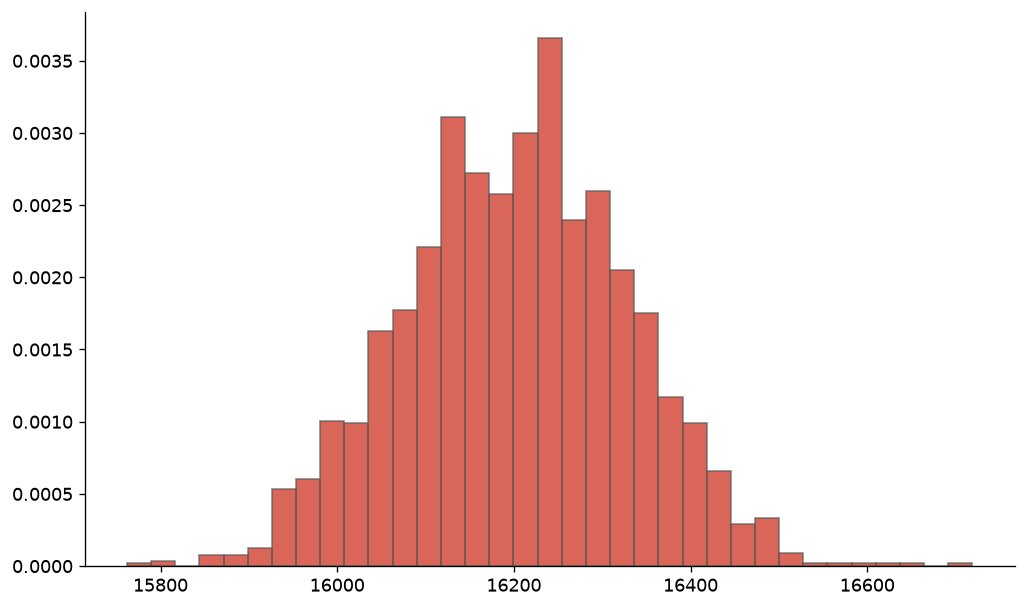

media simulata: 16202.79

valore atteso: 16201.23

scarto relativo: 0.0001 (0.01%)
errore media simulazione: 2.82



In [53]:
#distribuzione dello stimatore

M=2000
matrice_simulata = rng.poisson(mu(x), size=(M, len(x)))
N_c_j = np.sum(matrice_simulata[:,regione_centrale], axis=1)

media_simulata = np.mean(N_c_j)
dev_std_simulata = np.std(N_c_j, ddof=1)

errore_media_simulata = dev_std_simulata / np.sqrt(M)
scarto_relativo_media = np.abs(media_simulata - mu_c) / mu_c 
sigma_teorico = np.sqrt(mu_c)

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(N_c_j, bins='auto', density=True, color = ROSSO, edgecolor = GRIGIO, alpha =0.7, label = "distribuzione empiria")
plt.show()

print(f"media simulata: {media_simulata:.2f}\n")
print(f"valore atteso: {mu_c:.2f}\n")
print(f"scarto relativo: {scarto_relativo_media:.4f} ({scarto_relativo_media*100:.2f}%)")
print(f"errore media simulazione: {errore_media_simulata:.2f}\n")



      

In [ ]:
sto scrivendo altre cose lalala

: 